# Module 3: Land Classification: CNN-Transformer Integration Evaluation

> **Assignment (8 points):** Final evaluation of the Keras and PyTorch CNN-ViT hybrid models on the land classification task.

In [1]:
import os, sys, pathlib, warnings
warnings.filterwarnings('ignore')
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
PROJECT_ROOT = pathlib.Path(os.path.abspath(os.getcwd()))
for p in [PROJECT_ROOT] + list(PROJECT_ROOT.parents):
    if (p / 'images_dataSAT').is_dir():
        PROJECT_ROOT = p
        break
os.chdir(PROJECT_ROOT)
print('Project root:', PROJECT_ROOT)

Project root: D:\امتحان


In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import torch
import torch.nn as nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, roc_auc_score, roc_curve)

## Shared evaluation helper: `print_metrics`

In [3]:
def print_metrics(y_true, y_pred, model_name):
    acc  = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    rec  = recall_score(y_true, y_pred)
    f1   = f1_score(y_true, y_pred)
    cm   = confusion_matrix(y_true, y_pred)
    print(f'\n========== {model_name} ==========')
    print(f'Accuracy : {acc:.4f}')
    print(f'Precision: {prec:.4f}')
    print(f'Recall   : {rec:.4f}')
    print(f'F1 score : {f1:.4f}')
    print(f'Confusion matrix:\n{cm}')

    auc = roc_auc_score(y_true, y_pred)
    fpr, tpr, _ = roc_curve(y_true, y_pred)
    plt.figure(figsize=(5, 4))
    plt.plot(fpr, tpr, label=f'{model_name} (AUC={auc:.3f})')
    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC Curve')
    plt.legend()
    plt.grid(True)
    os.makedirs('models', exist_ok=True)
    plt.savefig(f'models/roc_{model_name.replace(" ", "_")}.png')
    plt.show()

    return {'accuracy': acc, 'precision': prec, 'recall': rec, 'f1': f1,
            'confusion_matrix': cm, 'auc': auc}

### Task 1: Define the dataset directory, dataloader and model hyperparameters (same as used during training)

In [4]:
data_dir = './images_dataSAT'
BATCH_SIZE = 32

val_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])
val_dataset = datasets.ImageFolder(data_dir, transform=val_transform)
val_dataset, _ = random_split(val_dataset, [400, len(val_dataset) - 400])
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

# Model hyperparameters (identical to training)
EMBED_DIM = 768
NUM_HEADS = 12
TRANSFORMER_DEPTH = 12

### Task 2: Instantiate the PyTorch model

In [5]:
class CNNViTHybrid(nn.Module):
    def __init__(self, embed_dim=128, num_heads=4, transformer_depth=4, num_classes=1):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(128, 256, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.num_patches = 4 * 4
        self.patch_embed = nn.Linear(256, embed_dim)
        self.pos_embed = nn.Parameter(torch.randn(1, self.num_patches, embed_dim) * 0.02)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim, nhead=num_heads, dim_feedforward=4 * embed_dim,
            batch_first=True, dropout=0.1, norm_first=True)
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=transformer_depth)
        self.head = nn.Sequential(nn.LayerNorm(embed_dim), nn.Linear(embed_dim, num_classes))

    def forward(self, x):
        x = self.cnn(x)
        B, C, H, W = x.shape
        x = x.permute(0, 2, 3, 1).reshape(B, H * W, C)
        x = self.patch_embed(x) + self.pos_embed
        x = self.transformer(x)
        x = x.mean(dim=1)
        return self.head(x)


model_pt = CNNViTHybrid(embed_dim=EMBED_DIM, num_heads=NUM_HEADS, transformer_depth=TRANSFORMER_DEPTH)
model_pt.load_state_dict(torch.load('models/pytorch_vit_test.pth', map_location='cpu', weights_only=True))
model_pt.eval()
print('PyTorch hybrid model instantiated (768 / 12 / 12)')

y_true_pt = []
y_prob_pt = []
with torch.no_grad():
    for images, labels in val_loader:
        out = torch.sigmoid(model_pt(images))
        y_prob_pt.extend(out.squeeze(1).tolist())
        y_true_pt.extend(labels.tolist())

y_true_pt = np.array(y_true_pt)
y_pred_pt = (np.array(y_prob_pt) > 0.5).astype(int).flatten()

PyTorch hybrid model instantiated (768 / 12 / 12)


### Task 3: Print the evaluation metrics for the **Keras** ViT model named `Keras CNN-Vit Hybrid Model`

Found 6000 images belonging to 2 classes.



========== Keras CNN-Vit Hybrid Model ==========
Accuracy : 0.9247
Precision: 0.9586
Recall   : 0.8877
F1 score : 0.9218
Confusion matrix:
[[2885  115]
 [ 337 2663]]


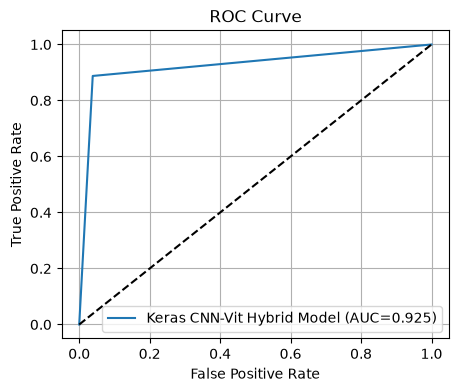

In [6]:
keras_vit = tf.keras.models.load_model('models/vit_hybrid.keras')

datagen = ImageDataGenerator(rescale=1. / 255)
test_generator = datagen.flow_from_directory(
    data_dir, target_size=(64, 64), batch_size=BATCH_SIZE,
    class_mode='binary', shuffle=False, seed=42)

y_true_keras = test_generator.classes
y_prob_keras = keras_vit.predict(test_generator, verbose=0).flatten()
y_pred_keras = (y_prob_keras > 0.5).astype(int).flatten()

keras_metrics = print_metrics(y_true_keras, y_pred_keras, 'Keras CNN-Vit Hybrid Model')

### Task 4: Print the evaluation metrics for the **PyTorch** ViT model named `PyTorch CNN-Vit Hybrid Model`


========== PyTorch CNN-Vit Hybrid Model ==========
Accuracy : 0.8300
Precision: 0.7857
Recall   : 0.9167
F1 score : 0.8462
Confusion matrix:
[[145  51]
 [ 17 187]]


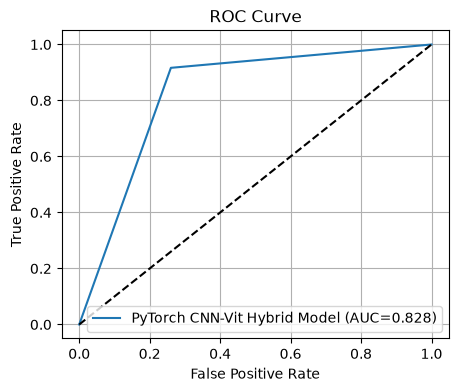

In [7]:
torch_metrics = print_metrics(y_true_pt, y_pred_pt, 'PyTorch CNN-Vit Hybrid Model')

## Final comparison

In [8]:
print(f'{"Metric":<12}{"Keras CNN-Vit":<16}{"PyTorch CNN-Vit":<16}')
for key in ['accuracy', 'precision', 'recall', 'f1', 'auc']:
    print(f'{key:<12}{keras_metrics[key]:<16.4f}{torch_metrics[key]:<16.4f}')

Metric      Keras CNN-Vit   PyTorch CNN-Vit 
accuracy    0.9247          0.8300          
precision   0.9586          0.7857          
recall      0.8877          0.9167          
f1          0.9218          0.8462          
auc         0.9247          0.8282          
